In [125]:
import os
import numpy as np
import pandas as pd
from scipy.optimize import least_squares
from scipy.stats import linregress
from scipy.spatial.distance import cdist
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

from Bio import SeqIO

sns.set_theme(style="whitegrid", context="notebook")

In [126]:
SERO = range(1, 5)


AA_SEQS_EXP_E_MAP="../resources/experimental_data/AA_sequences/E_DENV{}_aa_E_map.fasta"
META_EXP = "../resources/experimental_data/metadata/E_DENV{}_meta.tsv"

DIST_EPITOPE_GRANTHAM = "../output/distances_epitope_grantham_DENV{sero}.csv"
DIST_EPITOPE_GRANTHAM_VAL = "../output/validation_distances_epitope_grantham_DENV{sero}.csv"
DIST_ALL_GRANTHAM_VAL = "../output/validation_distances_all_grantham_DENV{sero}.csv"
DIST_EPITOPE_HAMMING_VAL = "../output/validation_distances_epitope_hamming_DENV{sero}.csv"
DIST_ALL_HAMMING_VAL = "../output/validation_distances_all_hamming_DENV{sero}.csv"

## Cargar Matriz de distancias

### Matrices de distancia Grantaham epitópico

In [193]:
dfs_epi_grantham = []
for sero in SERO:
    filename = DIST_EPITOPE_GRANTHAM.format(sero=sero)
    if not os.path.exists(filename):
        raise FileNotFoundError(f"No existe el archivo para DENV{sero}: {filename}")

    dfs_epi_grantham.append(pd.read_csv(filename, index_col=0))
    print(f"Matriz de DENV{sero} cargada desde: {filename}")

df_matrices = dfs_epi_grantham

Matriz de DENV1 cargada desde: ../output/distances_epitope_grantham_DENV1.csv
Matriz de DENV2 cargada desde: ../output/distances_epitope_grantham_DENV2.csv
Matriz de DENV3 cargada desde: ../output/distances_epitope_grantham_DENV3.csv
Matriz de DENV4 cargada desde: ../output/distances_epitope_grantham_DENV4.csv


## Cargar mapa antigénico

In [142]:
mapa_ag = pd.read_csv(
    "../resources/experimental_data/2d-antigenic-map.txt",
    sep=r"\s+",
    header=None,
    names=["type", "strainID", "coord1", "coord2"]
)

# Extraer serotipo: acepta DENV1 y DEN1
mapa_ag["sero_num"] = mapa_ag["strainID"].str.extract(
    r"(?:DENV|DEN)(\d)",
    expand=False
)

mapa_ag["sero"] = "DENV" + mapa_ag["sero_num"]

### Figura: mapa antigénico

Antígenos: 412
Antisueros: 36


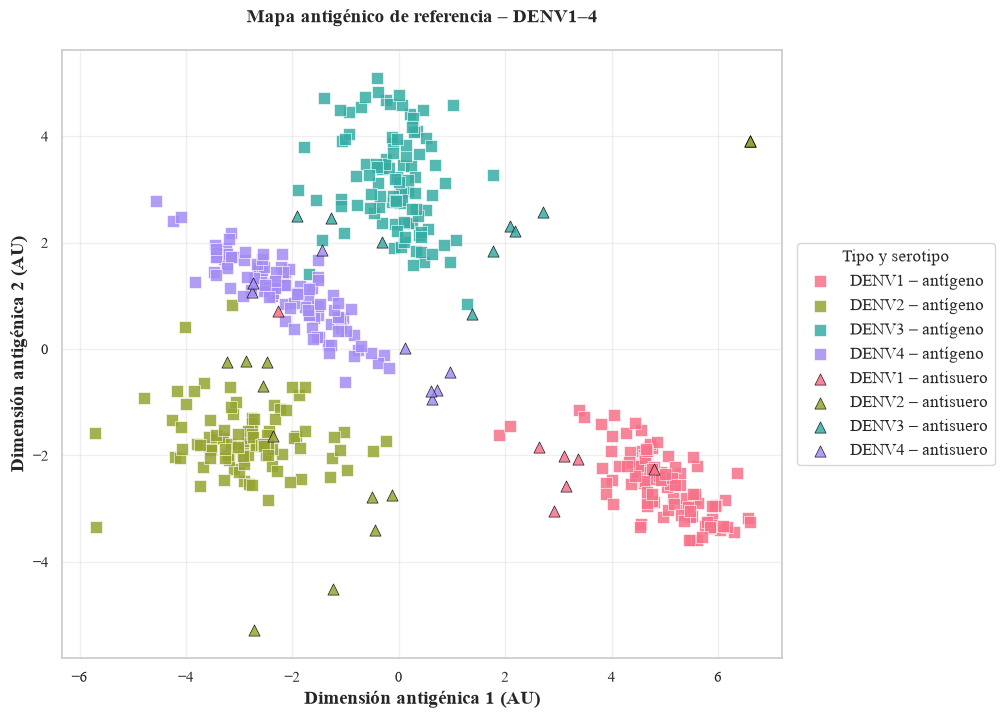

In [130]:
plt.rcParams["font.family"] = "Times New Roman"

# Separar antígenos y antisueros
antigenos = mapa_ag[mapa_ag["type"] == "AG"].copy()
sueros = mapa_ag[mapa_ag["type"] == "SR"].copy()

print(f"Antígenos: {len(antigenos)}")
print(f"Antisueros: {len(sueros)}")

unique_sero = sorted(mapa_ag["sero"].unique())

palette = sns.color_palette(
    "husl",
    n_colors=len(unique_sero)
)

color_dict = dict(zip(unique_sero, palette))

fig, ax = plt.subplots(figsize=(15, 8))
fig.subplots_adjust(
    left=0.10,
    right=0.75,
    bottom=0.12,
    top=0.88
)

for sero in unique_sero:
    df = antigenos[antigenos["sero"] == sero]

    ax.scatter(
        df["coord1"],
        df["coord2"],
        color=color_dict[sero],
        marker="s",
        s=65,
        alpha=0.85,
        edgecolors="white",
        linewidth=0.5,
        label=f"{sero} – antígeno"
    )


for sero in unique_sero:
    df = sueros[sueros["sero"] == sero]

    ax.scatter(
        df["coord1"],
        df["coord2"],
        color=color_dict[sero],
        marker="^",
        s=65,
        alpha=0.85,
        edgecolors="black",
        linewidth=0.5,
        label=f"{sero} – antisuero"
    )


ax.set_xlabel(
    "Dimensión antigénica 1 (AU)",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel(
    "Dimensión antigénica 2 (AU)",
    fontsize=14,
    fontweight="bold"
)

ax.set_title(
    "Mapa antigénico de referencia – DENV1–4",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.grid(
    True,
    alpha=0.3
)

# Leyenda
ax.legend(
    title="Tipo y serotipo",
    title_fontsize=12,
    fontsize=12,
    frameon=True,
    ncol=1,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    borderaxespad=0
)
ax.set_aspect("equal", adjustable="box")
plt.savefig(
    "../figures/mapa_ref.png",
    dpi=300,
    bbox_inches="tight"
)

### Cargar Metadata de las secuencias de referencia

In [131]:
info_viruses = pd.read_csv(
    "../resources/experimental_data/metadata/information.viruses.csv"
)

### Tabla: Caracteristicas secuencias de referencia

In [132]:
# Si antigenos ya tiene genotype, eliminarlo antes del merge
if "genotype" in antigenos.columns:
    antigenos = antigenos.drop(columns=["genotype"])

# Información de genotipo
info_genotype = (
    info_viruses[
        ["unified.sequence.names", "genotype"]
    ]
    .drop_duplicates(subset="unified.sequence.names")
)

# Agregar genotipo
antigenos = antigenos.merge(
    info_genotype,
    left_on="strainID",
    right_on="unified.sequence.names",
    how="left"
)

# Eliminar columna auxiliar
antigenos = antigenos.drop(columns=["unified.sequence.names"])

# País
antigenos["country"] = (
    antigenos["strainID"]
    .str.split("/")
    .str[1]
    .str.strip()
    .str.title()
)

# Distribución de genotipos por serotipo
tabla_genotipos = (
    antigenos
    .groupby(["sero", "genotype"])
    .size()
    .reset_index(name="n")
)

tabla = (
    antigenos
    .groupby(["sero", "genotype"])
    .agg(
        n=("strainID", "size"),
        paises=("country", lambda x: ", ".join(sorted(x.unique())))
    )
    .reset_index()
)

# Ordenar genotipos por frecuencia dentro de cada serotipo
tabla = (
    tabla
    .sort_values(["sero", "n"], ascending=[True, False])
)

print(tabla.to_string(index=False))

 sero             genotype  n                                                       paises
DENV1              DENV1-I 95                         Cambodia, Myanmar, Thailand, Vietnam
DENV1              DENV1-V  8               Bolivia, Peru, Puertorico, Thailand, Venezuela
DENV1             DENV1-II  1                                                     Thailand
DENV1             DENV1-IV  1                                                        Nauru
DENV2        DENV2-Asian I 83                                           Cambodia, Thailand
DENV2 DENV2-Asian/American  7                 Brazil, Guyana, Nicaragua, Thailand, Vietnam
DENV2   DENV2-Cosmopolitan  4                                     India, Thailand, Vietnam
DENV2       DENV2-American  2                                                  Peru, Tonga
DENV2       DENV2-Sylvatic  2                                            Malaysia, Senegal
DENV2       DENV2-Asian II  1                                                    Newguinea

### [FIX: DATOS POR LINAJE]Figura: Distribución temporal de las secuencias asociadas al mapa antigénico

DENV1: 105 secuencias presentes en el mapa antigénico
DENV2: 86 secuencias presentes en el mapa antigénico
DENV3: 102 secuencias presentes en el mapa antigénico
DENV4: 92 secuencias presentes en el mapa antigénico


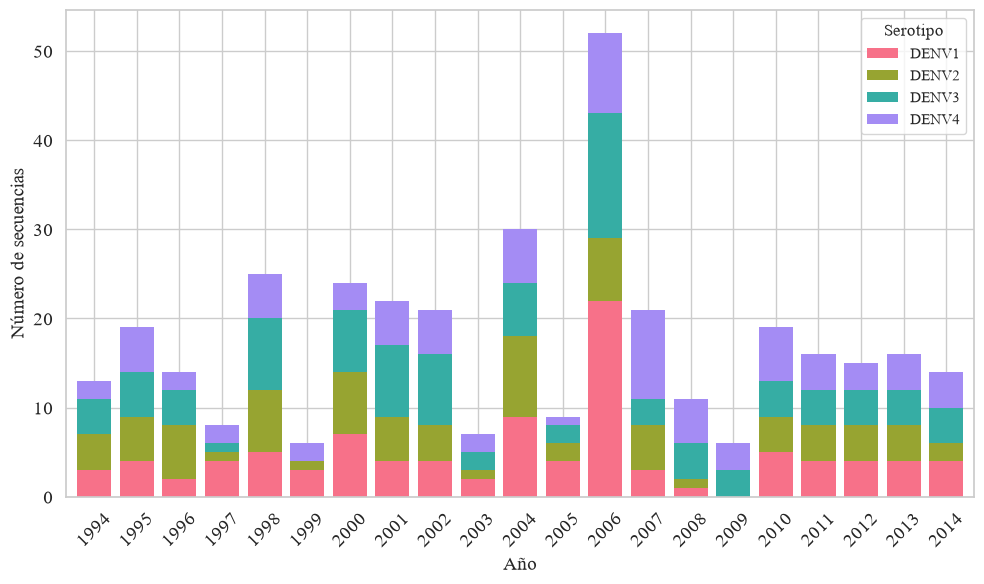

In [133]:
plt.rcParams["font.family"] = "Times New Roman"

plot_data = []

for sero in range(1, 5):
    
    fasta_file = AA_SEQS_EXP_E_MAP.format(sero)

    records = list(SeqIO.parse(fasta_file, "fasta"))

    valid_ids = {
        record.id.strip()
        for record in records
    }

    print(
        f"DENV{sero}: {len(valid_ids)} secuencias "
        f"presentes en el mapa antigénico"
    )

    df = pd.read_csv(
        META_EXP.format(sero),
        sep="\t"
    )

    df["strain"] = (
        df["strain"]
        .astype(str)
        .str.strip()
    )

    df = df[
        df["strain"].isin(valid_ids)
    ].copy()

    df["date"] = pd.to_datetime(
        df["date"],
        format="mixed",
        errors="coerce"
    )

    df = df.dropna(subset=["date"])

    df["year"] = df["date"].dt.year

    counts = (
        df.groupby("year")
        .size()
        .reindex(
            range(1994, 2015),
            fill_value=0
        )
        .reset_index()
    )

    counts.columns = [
        "year",
        "count"
    ]

    counts["serotype"] = f"DENV{sero}"

    plot_data.append(counts)


plot_df = pd.concat(
    plot_data,
    ignore_index=True
)


plot_pivot = plot_df.pivot(
    index="year",
    columns="serotype",
    values="count"
).fillna(0)

plot_pivot = plot_pivot[
    ["DENV1", "DENV2", "DENV3", "DENV4"]
]


fig, ax = plt.subplots(
    figsize=(10, 6)
)

plot_pivot.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=sns.color_palette("husl", 4),
    width=0.8,
    linewidth=0
)

ax.set_xlabel(
    "Año",
    fontsize=14
)

ax.set_ylabel(
    "Número de secuencias",
    fontsize=14
)
'''
ax.set_title(
    "Distribución temporal de las secuencias asociadas al mapa antigénico",
    fontsize=14,
    fontweight="bold"
)
'''
ax.legend(
    title="Serotipo"
)

ax.tick_params(
    axis="x",
    rotation=45,
    labelsize=14
)
ax.tick_params(
    axis="y",
    labelsize=14
)

plt.tight_layout()
plt.savefig("../figures/distribucion_temporal_ref.png",
            dpi=300, bbox_inches="tight")
plt.show()

### [FIX MEJORAR HEATMAP]Figura: heatmap de secuencias colombianas

D:\EQUIPO\Documents HDD\Tesis\denv-cross-inmunity\.venv\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
D:\EQUIPO\Documents HDD\Tesis\denv-cross-inmunity\.venv\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


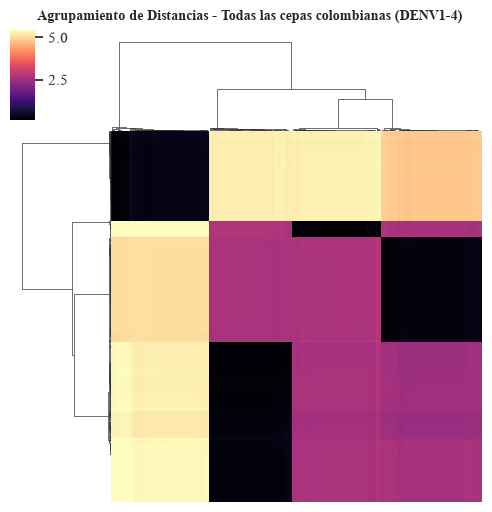

  Guardado: clustermap_DENV_all_combined.png


In [134]:
combined_df = pd.concat(df_matrices, axis=0)

g = sns.clustermap(
    combined_df, 
    cmap='magma', 
    xticklabels=False, 
    yticklabels=False,
    figsize=(5, 5),
    robust=True
)

g.fig.suptitle('Agrupamiento de Distancias - Todas las cepas colombianas (DENV1-4)', y=1.02, fontsize=10, fontweight='bold')
g.savefig('../figures/clustermap_DENV_all_combined.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

print("  Guardado: clustermap_DENV_all_combined.png")

### [FIX MEJORAR LINAJES PARA EXP Y REF]Figura: Referencia mas cercana a las secuencias colombianas

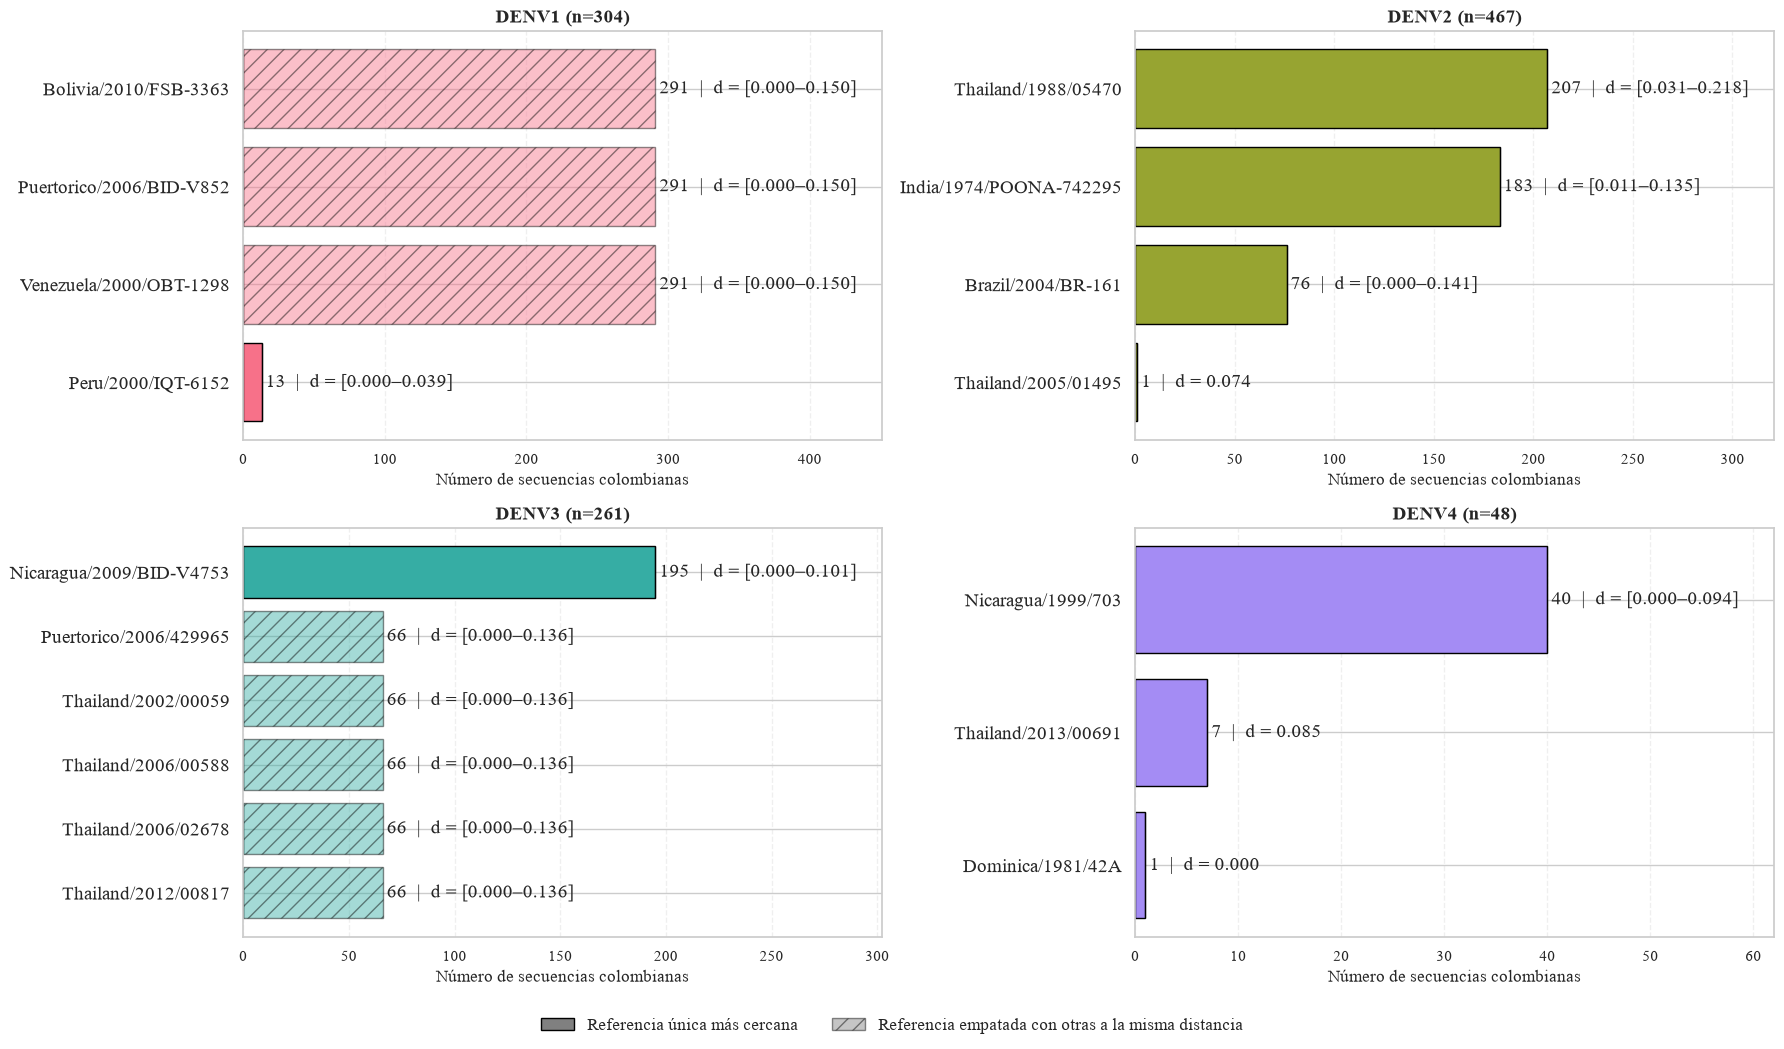

In [135]:
def ref_label(ref_id):
    p = ref_id.split("/")
    pais = p[1].title()
    anio = p[2]
    rid  = p[3]
    return f"{pais}/{anio}/{rid}"

def country(ref_id):
    return ref_id.split("/")[1].title()

def fmt_dist(vals):
    vals = np.asarray(vals, dtype=float)
    lo, hi = vals.min(), vals.max()
    if np.isclose(lo, hi, atol=1e-9):
        return f"d = {lo:.3f}"
    return f"d = [{lo:.3f}–{hi:.3f}]"
atol = 1e-9
# ---- 1) Tabla detallada ----
rows = []
for sero, matrix in zip(SERO, df_matrices):
    d = matrix.values.astype(float)
    for i, strain in enumerate(matrix.index):
        if np.isnan(d[i]).all():
            continue
        dmin = np.nanmin(d[i])
        tied_refs = list(matrix.columns[np.isclose(d[i], dmin, atol=atol)])
        rows.append({
            "serotype": sero,
            "seq_col": strain,
            "min_distance": dmin,
            "n_refs_tied": len(tied_refs),
            "n_countries_tied": len({country(r) for r in tied_refs}),
            "countries_tied": ";".join(sorted({country(r) for r in tied_refs})),
            "labels_tied": ";".join(ref_label(r) for r in tied_refs),
            "refs_tied": ";".join(tied_refs),
        })
df_matches = pd.DataFrame(rows)
#df_matches.to_csv("../output/closest_matches_detail.tsv", sep="\t", index=False)

# ---- 2) Figura ----
top_n = 10
colors = sns.color_palette("husl", n_colors=len(SERO))
fig, axes = plt.subplots(2, 2, figsize=(18, 11))

for ax, sero, color in zip(axes.flatten(), SERO, colors):
    sub = df_matches[df_matches.serotype == sero]

    uniq, tied = {}, {}
    dist_by_label = {}
    for _, r in sub.iterrows():
        target = uniq if r.n_refs_tied == 1 else tied
        for lab in r.labels_tied.split(";"):
            target[lab] = target.get(lab, 0) + 1
            dist_by_label.setdefault(lab, []).append(r.min_distance)

    cnt = pd.DataFrame({"unico": pd.Series(uniq, dtype=float),
                        "empatado": pd.Series(tied, dtype=float)}).fillna(0)
    cnt["total"] = cnt.sum(axis=1)
    cnt = cnt.sort_values("total", ascending=False).head(top_n).iloc[::-1]

    ax.barh(cnt.index, cnt["unico"], color=color, edgecolor="black")
    ax.barh(cnt.index, cnt["empatado"], left=cnt["unico"], color=color, alpha=0.45,
            edgecolor="black", hatch="//")

    xmax = cnt["total"].max()
    for y, (lab, u, t) in enumerate(zip(cnt.index, cnt["unico"], cnt["empatado"])):
        ax.text(u + t + xmax * 0.01, y,
                f"{int(u + t)}  |  {fmt_dist(dist_by_label[lab])}",
                va="center", fontsize=14)

    pct_tied = (sub.n_refs_tied > 1).mean() * 100
    ax.set_title(f"DENV{sero} (n={len(sub)})", fontsize=14, fontweight="bold")
    ax.set_xlabel("Número de secuencias colombianas")
    ax.tick_params(axis="y", labelsize=14)
    ax.grid(axis="x", alpha=0.3, linestyle="--")
    ax.set_xlim(0, xmax * 1.55)

handles = [Patch(facecolor="grey", edgecolor="black", label="Referencia única más cercana"),
           Patch(facecolor="grey", alpha=0.45, edgecolor="black", hatch="//",
                 label="Referencia empatada con otras a la misma distancia")]
fig.legend(handles=handles, loc="lower center", ncol=2, fontsize=12, frameon=False)
#fig.suptitle("Referencias experimentales más cercanas a las secuencias colombianas",fontsize=18, fontweight="bold")
plt.tight_layout(rect=[0, 0.04, 1, 0.96])
plt.savefig("../figures/closest_experimental_matches.png", dpi=300, bbox_inches="tight")
plt.show()

## Proyección secuencias colombianas al mapa antigénico

In [199]:
def project_one(d, ref_xy, scale=None, eps=1e-6):
    d = np.asarray(d, dtype=float)
    ref_xy = np.asarray(ref_xy, dtype=float)

    valid = ~np.isnan(d)
    if valid.sum() < 3:                      # underdetermined: fall back to centroid
        return ref_xy.mean(axis=0)
    d, ref = d[valid], ref_xy[valid]

    w = 1.0 / (d + eps)
    w /= w.mean()                            # mean 1, so tolerances behave
    sw = np.sqrt(w)                          # proper weighting: cost = sum(w * r^2)
    a0 = (w[:, None] * ref).sum(0) / w.sum()

    if scale is None:
        mx = d.max()
        target = d / mx if mx > 0 else d     # assumes ref_xy is on a unit scale
    else:
        target = np.maximum(scale[0] * d + scale[1], 0.0)

    res = lambda a: sw * (np.linalg.norm(ref - a, axis=1) - target)
    sol = least_squares(res, a0, method='lm', max_nfev=100,
                        ftol=1e-8, xtol=1e-8, gtol=1e-8)
    return sol.x if sol.status > 0 else a0

In [200]:
def project_strains(df_matrices, mapa_ag, scales=None, same_sero_only=False):
    """Para cepas que NO están en el mapa (p. ej. las colombianas)."""
    m = mapa_ag.drop_duplicates(subset='strainID').set_index('strainID')
    cols = df_matrices[0].columns.tolist()
    ref_xy = m.reindex(cols)[['coord1', 'coord2']].values
    col_sero = m.reindex(cols)['sero_num'].astype(int).values

    # Aviso si alguna cepa a proyectar ya está entre las referencias (fuga)
    for s in [1, 2, 3, 4]:
        overlap = set(df_matrices[s - 1].index) & set(cols)
        if overlap:
            print(f"DENV{s}: {len(overlap)} cepas también están en las referencias")

    out = {}
    for s in [1, 2, 3, 4]:
        dfm = df_matrices[s - 1]
        keep = (col_sero == s) if same_sero_only else np.ones(len(cols), bool)
        sc = scales[s] if scales else None
        xy = np.array([project_one(row[keep], ref_xy[keep], sc) for row in dfm.values])
        out[s] = pd.DataFrame(xy, index=dfm.index, columns=['X', 'Y'])
    return out

In [201]:
projected_coordinates = project_strains(df_matrices, mapa_ag)
[print(f"{key}: {value.head()}") for key, value in projected_coordinates.items()]

1:                                                    X         Y
DenV1/mosquito/Colombia/MAG-CIST-0134/2018  6.361016 -2.805690
DenV1/mosquito/Colombia/MAG-CIST-0151/2018  6.361016 -2.805690
DenV1/un/Colombia/un-UniNorte-1/2001        3.699348 -2.026686
hDenV1/Colombia/ANT-INS-485061/2016         6.361016 -2.805690
hDenV1/Colombia/ANT-UDEA-COA0053/2021       6.361016 -2.805690
2:                                                 X         Y
DenV2/Colombia/VAC-LSPVAC-01056-VI/2024 -2.381836 -1.593061
DenV2/Colombia/VAC-LSPVAC-01460-VI/2024 -2.217739 -1.458035
DenV2/Colombia/VAC-LSPVAC-01585-VI/2024 -2.217739 -1.458035
DenV2/Colombia/VAC-LSPVAC-01723-VI/2024 -2.217739 -1.458035
DenV2/Colombia/VAC-LSPVAC-01759-VI/2024 -2.026198 -1.468500
3:                                              X         Y
hDenV3/Colombia/ANT-UDS-0109587/2012 -1.887614  2.979523
hDenV3/Colombia/ANT-UDS-0221590/2013 -1.887614  2.979523
hDenV3/Colombia/ANT-UDS-0267594/2014 -1.887614  2.979523
hDenV3/Colombia/ANT-UDS-0

[None, None, None, None]

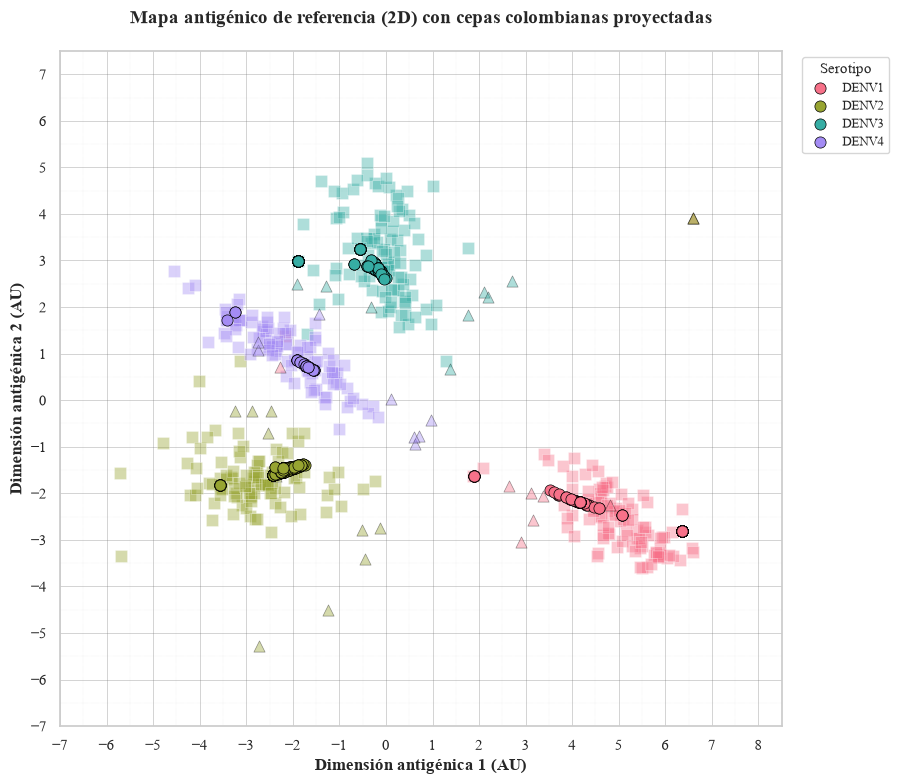

In [202]:
fig, ax = plt.subplots(figsize=(15, 8))
fig.subplots_adjust(
    left=0.10,
    right=0.75,
    bottom=0.12,
    top=0.88
)

# Referencia (Antígenos)
for sero in unique_sero:
    df = antigenos[antigenos["sero"] == sero]
    ax.scatter(
        df["coord1"], df["coord2"],
        color=color_dict[sero],
        marker="s",
        s=65,
        alpha=0.4,
        edgecolors="white",
        linewidth=0.5
    )

# Referencia (Antisueros)
for sero in unique_sero:
    df = sueros[sueros["sero"] == sero]
    ax.scatter(
        df["coord1"], df["coord2"],
        color=color_dict[sero],
        marker="^",
        s=65,
        alpha=0.4,
        edgecolors="black",
        linewidth=0.5
    )

# Cepas Colombianas Proyectadas
for sero in [1, 2, 3, 4]:
    sero_str = f"DENV{sero}"
    if sero in projected_coordinates:
        df_proj = projected_coordinates[sero]
        ax.scatter(
            df_proj["X"], df_proj["Y"],
            color=color_dict[sero_str],
            marker="o",
            s=65,
            alpha=1,
            edgecolors="black",
            linewidth=0.5,
            label=f"{sero_str}"
        )




all_x = np.concatenate([
    antigenos["coord1"].values,
    sueros["coord1"].values,
    *[projected_coordinates[s]["X"].values for s in projected_coordinates]
])
all_y = np.concatenate([
    antigenos["coord2"].values,
    sueros["coord2"].values,
    *[projected_coordinates[s]["Y"].values for s in projected_coordinates]
])

x_min, x_max = np.floor(all_x.min()) - 1, np.ceil(all_x.max()) + 1
y_min, y_max = np.floor(all_y.min()) - 1, np.ceil(all_y.max()) + 1

ax.set_xticks(np.arange(x_min, x_max + 1, 1))
ax.set_yticks(np.arange(y_min, y_max + 1, 1))

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.grid(
    True,
    which="major",
    linestyle="-",
    linewidth=0.6,
    color="gray",
    alpha=0.4
)

ax.set_xticks(np.arange(x_min, x_max + 1, 0.5), minor=True)
ax.set_yticks(np.arange(y_min, y_max + 1, 0.5), minor=True)
ax.grid(
    True,
    which="minor",
    linestyle=":",
    linewidth=0.3,
    color="gray",
    alpha=0.25
)




ax.set_xlabel(
    "Dimensión antigénica 1 (AU)",
    fontsize=12,
    fontweight="bold"
)
ax.set_ylabel(
    "Dimensión antigénica 2 (AU)",
    fontsize=12,
    fontweight="bold"
)
ax.set_title(
    "Mapa antigénico de referencia (2D) con cepas colombianas proyectadas",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.legend(
    title="Serotipo",
    title_fontsize=11,
    fontsize=9,
    frameon=True,
    ncol=1,
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)
ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.savefig(
    "../figures/mapa_proy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Validación

## Cargar Matriz de distancias de validación

### Matrices validación de distancia Grantaham epitópico

In [203]:
dfs_epi_grantham_val = []
for sero in SERO:
    filename = DIST_EPITOPE_GRANTHAM_VAL.format(sero=sero)
    if not os.path.exists(filename):
        raise FileNotFoundError(f"No existe el archivo para DENV{sero}: {filename}")

    dfs_epi_grantham_val.append(pd.read_csv(filename, index_col=0))
    print(f"Matriz de DENV{sero} cargada desde: {filename}")

Matriz de DENV1 cargada desde: ../output/validation_distances_epitope_grantham_DENV1.csv
Matriz de DENV2 cargada desde: ../output/validation_distances_epitope_grantham_DENV2.csv
Matriz de DENV3 cargada desde: ../output/validation_distances_epitope_grantham_DENV3.csv
Matriz de DENV4 cargada desde: ../output/validation_distances_epitope_grantham_DENV4.csv


### Matrices validación de distancia Grantaham todo el gen E

In [204]:
dfs_all_grantham_val = []
for sero in SERO:
    filename = DIST_ALL_GRANTHAM_VAL.format(sero=sero)
    if not os.path.exists(filename):
        raise FileNotFoundError(f"No existe el archivo para DENV{sero}: {filename}")

    dfs_all_grantham_val.append(pd.read_csv(filename, index_col=0))
    print(f"Matriz de DENV{sero} cargada desde: {filename}")

Matriz de DENV1 cargada desde: ../output/validation_distances_all_grantham_DENV1.csv
Matriz de DENV2 cargada desde: ../output/validation_distances_all_grantham_DENV2.csv
Matriz de DENV3 cargada desde: ../output/validation_distances_all_grantham_DENV3.csv
Matriz de DENV4 cargada desde: ../output/validation_distances_all_grantham_DENV4.csv


### Matrices validación de distancia Hamming epitópico

In [205]:
dfs_epi_hamming_val = []
for sero in SERO:
    filename = DIST_EPITOPE_HAMMING_VAL.format(sero=sero)
    if not os.path.exists(filename):
        raise FileNotFoundError(f"No existe el archivo para DENV{sero}: {filename}")

    dfs_epi_hamming_val.append(pd.read_csv(filename, index_col=0))
    print(f"Matriz de DENV{sero} cargada desde: {filename}")

Matriz de DENV1 cargada desde: ../output/validation_distances_epitope_hamming_DENV1.csv
Matriz de DENV2 cargada desde: ../output/validation_distances_epitope_hamming_DENV2.csv
Matriz de DENV3 cargada desde: ../output/validation_distances_epitope_hamming_DENV3.csv
Matriz de DENV4 cargada desde: ../output/validation_distances_epitope_hamming_DENV4.csv


### Matrices validación de distancia Hamming todo el gen E

In [206]:
dfs_all_hamming_val = []
for sero in SERO:
    filename = DIST_ALL_HAMMING_VAL.format(sero=sero)
    if not os.path.exists(filename):
        raise FileNotFoundError(f"No existe el archivo para DENV{sero}: {filename}")

    dfs_all_hamming_val.append(pd.read_csv(filename, index_col=0))
    print(f"Matriz de DENV{sero} cargada desde: {filename}")

Matriz de DENV1 cargada desde: ../output/validation_distances_all_hamming_DENV1.csv
Matriz de DENV2 cargada desde: ../output/validation_distances_all_hamming_DENV2.csv
Matriz de DENV3 cargada desde: ../output/validation_distances_all_hamming_DENV3.csv
Matriz de DENV4 cargada desde: ../output/validation_distances_all_hamming_DENV4.csv


## Validación Leave-one-out

In [214]:
def validate_loo(df_matrices, mapa_ag, same_sero_only=False,
                 calibrate=False, drop_identical=False):
    m = mapa_ag.drop_duplicates(subset='strainID').set_index('strainID')
    cols = df_matrices[0].columns.tolist()
    ref_xy = m.reindex(cols)[['coord1', 'coord2']].values
    sizes = [len(d) for d in df_matrices]
    col_sero = np.repeat([1, 2, 3, 4], sizes)
    if calibrate:
        same_sero_only = True   # la escala se calibra intra-serotipo

    results = {}
    for s in [1, 2, 3, 4]:
        dfm = df_matrices[s - 1]
        ids = dfm.index.tolist()
        D = dfm.values.astype(float)
        in_s = (col_sero == s)

        if calibrate:
            Ds = D[:, in_s]                                  # n x n, mismo serotipo
            assert dfm.columns[in_s].tolist() == ids          # mismo orden filas/columnas
            Dm = cdist(m.loc[ids, ['coord1', 'coord2']].values,
                       m.loc[ids, ['coord1', 'coord2']].values)
            off = ~np.eye(len(ids), dtype=bool) & ~np.isnan(Ds)

        rows = []
        for i, sid in enumerate(ids):
            keep = np.array([c != sid for c in cols])          # quita la propia cepa por ID
            if same_sero_only:
                keep &= in_s
            if drop_identical:
                keep &= ~(D[i] <= 1e-9)                        # quita casi-duplicados (NaN -> False)
            d, ref = D[i, keep], ref_xy[keep]

            scale = None
            if calibrate:                                      # calibración SIN la cepa evaluada
                pm = off.copy(); pm[i, :] = False; pm[:, i] = False
                scale = np.polyfit(Ds[pm], Dm[pm], 1)

            px, py = project_one(d, ref, scale)

            # líneas base con los mismos candidatos (mismo serotipo, sin la propia)
            same = in_s & np.array([c != sid for c in cols])
            mean_xy = ref_xy[same].mean(axis=0)
            dd = np.where(np.isnan(D[i]), np.inf, D[i]); dd[~same] = np.inf
            nn_xy = ref_xy[np.argmin(dd)]

            rx, ry = m.loc[sid, ['coord1', 'coord2']]
            rows.append(dict(strainID=sid, real_X=rx, real_Y=ry, proj_X=px, proj_Y=py,
                             mean_X=mean_xy[0], mean_Y=mean_xy[1],
                             nn_X=nn_xy[0], nn_Y=nn_xy[1]))
        results[s] = pd.DataFrame(rows).set_index('strainID')
    return results


def resumen(results):
    out = []
    for s, df in results.items():
        def rmse(a, b):
            return np.sqrt(np.mean((df[f'{a}_X'] - df['real_X'])**2 +
                                   (df[f'{a}_Y'] - df['real_Y'])**2))
        r_p, r_m, r_n = rmse('proj', 'x'), rmse('mean', 'x'), rmse('nn', 'x')
        out.append(dict(Serotipo=f'DENV-{s}', n=len(df),
                        r_X=stats.pearsonr(df.real_X, df.proj_X)[0],
                        r_Y=stats.pearsonr(df.real_Y, df.proj_Y)[0],
                        RMSE_proy=r_p, RMSE_media=r_m, RMSE_vecino=r_n,
                        skill_vs_media=1 - r_p / r_m))
    return pd.DataFrame(out).round(4)

In [215]:
# Comparacion LOO de las cuatro metricas de distancia.
# Sin RMSE_vecino: solo proyeccion contra la linea base de la media del serotipo.
METRICAS = {
    "epitopo-Grantham": dfs_epi_grantham_val,
    "genE-Grantham":    dfs_all_grantham_val,
    "epitopo-Hamming":  dfs_epi_hamming_val,
    "genE-Hamming":     dfs_all_hamming_val,
}
VARIANTES = {
    "base":           dict(),
    "intra":          dict(same_sero_only=True),
    "calibrada":      dict(calibrate=True),
    "sin identicas":  dict(drop_identical=True),
}


def _filas(results, metrica, variante):
    out = []
    for s, df in results.items():
        def rmse(a):
            return np.sqrt(np.mean((df[f"{a}_X"] - df["real_X"]) ** 2 +
                                   (df[f"{a}_Y"] - df["real_Y"]) ** 2))

        def r2(eje):
            real, proy = df[f"real_{eje}"], df[f"proj_{eje}"]
            ss_res = ((real - proy) ** 2).sum()
            ss_tot = ((real - real.mean()) ** 2).sum()
            return 1 - ss_res / ss_tot      # negativo = peor que la media del eje

        r_p, r_m = rmse("proj"), rmse("mean")
        out.append(dict(Metrica=metrica, Variante=variante, Serotipo=f"DENV-{s}",
                        n=len(df),
                        r_X=stats.pearsonr(df.real_X, df.proj_X)[0],
                        r_Y=stats.pearsonr(df.real_Y, df.proj_Y)[0],
                        R2_X=r2("X"), R2_Y=r2("Y"),
                        RMSE_proy=r_p, RMSE_media=r_m,
                        skill=1 - r_p / r_m))
    return out


filas = []
for mname, mats in METRICAS.items():
    for vname, kw in VARIANTES.items():
        print(f"LOO: {mname} / {vname}")
        filas.extend(_filas(validate_loo(mats, mapa_ag, **kw), mname, vname))

comparacion = pd.DataFrame(filas).round(4)

# Resumen: mejora sobre la media del serotipo (positivo = la proyeccion aporta)
print("\nskill = 1 - RMSE_proy / RMSE_media\n")
print(comparacion.pivot_table(index=["Variante", "Serotipo"],
                              columns="Metrica", values="skill")
                 .reindex(columns=list(METRICAS)).round(3).to_string())

print("\nRMSE de proyeccion\n")
print(comparacion.pivot_table(index=["Variante", "Serotipo"],
                              columns="Metrica", values="RMSE_proy")
                 .reindex(columns=list(METRICAS)).round(3).to_string())

for eje in ("X", "Y"):
    print(f"\nR2 del eje {eje}\n")
    print(comparacion.pivot_table(index=["Variante", "Serotipo"],
                                  columns="Metrica", values=f"R2_{eje}")
                     .reindex(columns=list(METRICAS)).round(3).to_string())


LOO: epitopo-Grantham / base
LOO: epitopo-Grantham / intra
LOO: epitopo-Grantham / calibrada
LOO: epitopo-Grantham / sin identicas
LOO: genE-Grantham / base
LOO: genE-Grantham / intra
LOO: genE-Grantham / calibrada
LOO: genE-Grantham / sin identicas
LOO: epitopo-Hamming / base
LOO: epitopo-Hamming / intra
LOO: epitopo-Hamming / calibrada
LOO: epitopo-Hamming / sin identicas
LOO: genE-Hamming / base
LOO: genE-Hamming / intra
LOO: genE-Hamming / calibrada
LOO: genE-Hamming / sin identicas

skill = 1 - RMSE_proy / RMSE_media

Metrica                 epitopo-Grantham  genE-Grantham  epitopo-Hamming  genE-Hamming
Variante      Serotipo                                                                
base          DENV-1               0.010         -0.017           -0.002        -0.050
              DENV-2              -0.014         -0.035           -0.015        -0.033
              DENV-3               0.167          0.164            0.167         0.175
              DENV-4               0

## Figura: Validación leave-one-out epitopo-Grantham 

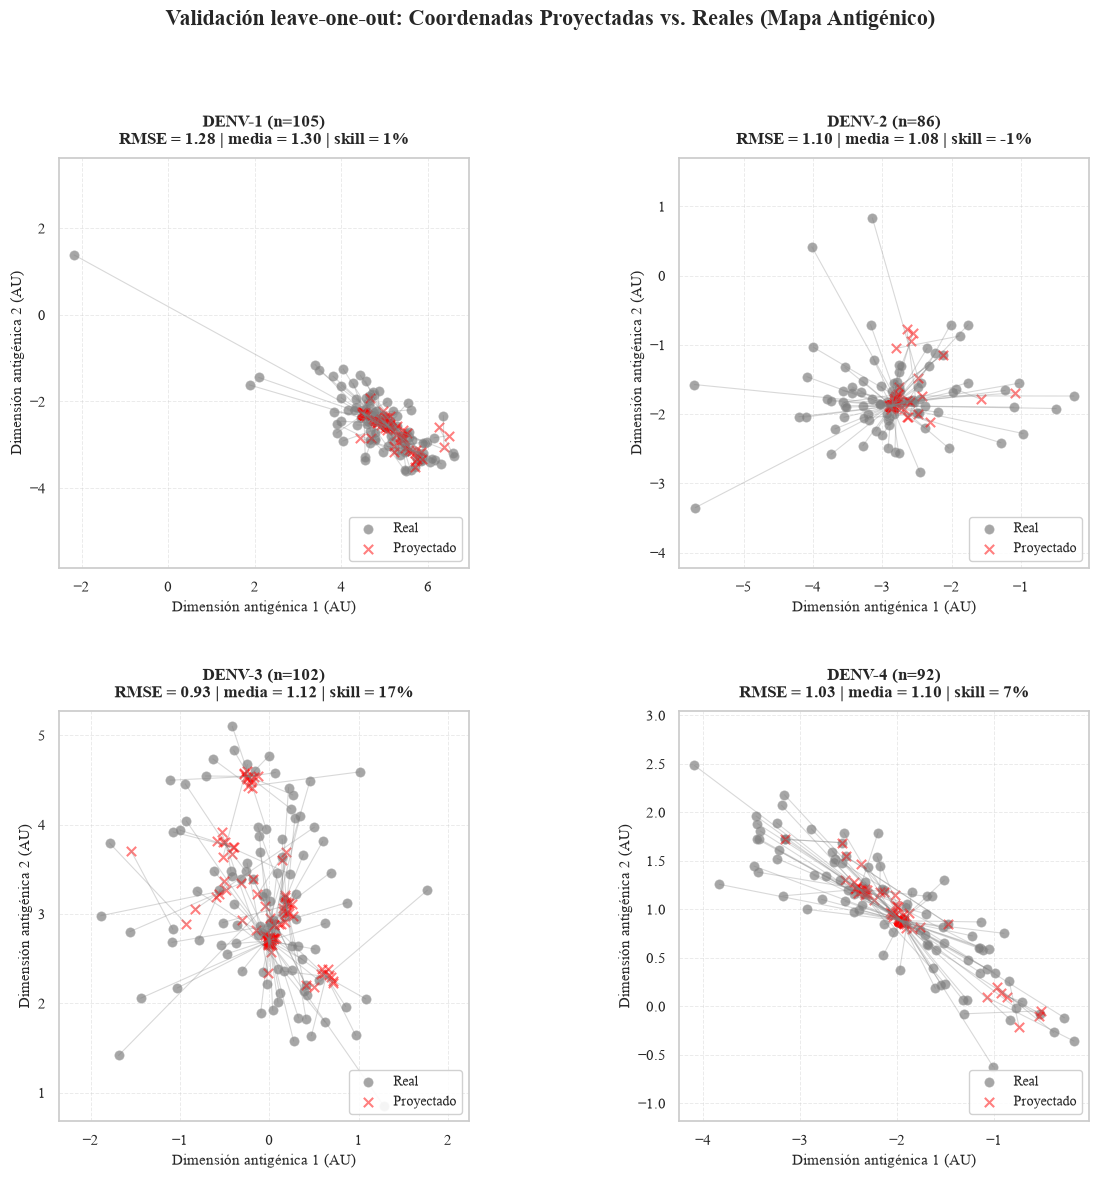

In [219]:
# 1) Validación leave-one-out (reemplaza project_strains_self)
base = validate_loo(dfs_epi_grantham_val, mapa_ag)

# 2) Mismo formato que antes: validation_results[sero] con error_X, error_Y, euclidean_error
validation_results = {}
for sero in [1, 2, 3, 4]:
    df_val = base[sero].reset_index()
    df_val['error_X'] = df_val['proj_X'] - df_val['real_X']
    df_val['error_Y'] = df_val['proj_Y'] - df_val['real_Y']
    df_val['euclidean_error'] = np.sqrt(df_val['error_X']**2 + df_val['error_Y']**2)
    # error de la línea base (media del serotipo sin la propia cepa)
    df_val['euclidean_error_media'] = np.sqrt((df_val['mean_X'] - df_val['real_X'])**2 +
                                              (df_val['mean_Y'] - df_val['real_Y'])**2)
    validation_results[sero] = df_val


# 4) Figura: paneles cuadrados, con RMSE y mejora vs. media en cada título
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes = axes.flatten()

for idx, sero in enumerate([1, 2, 3, 4]):
    df_val = validation_results[sero]
    ax = axes[idx]
    row = df_summary.iloc[idx]

    for i in range(len(df_val)):
        ax.plot([df_val.iloc[i]['real_X'], df_val.iloc[i]['proj_X']],
                [df_val.iloc[i]['real_Y'], df_val.iloc[i]['proj_Y']],
                color='gray', alpha=0.3, linewidth=0.8)

    ax.scatter(df_val['real_X'], df_val['real_Y'], alpha=0.7, s=45,
               c='grey', label='Real', marker='o', edgecolors='darkgrey', linewidth=0.5)
    ax.scatter(df_val['proj_X'], df_val['proj_Y'], alpha=0.5, s=45,
               c='red', label='Proyectado', marker='x', linewidth=1.5)

    all_x = np.concatenate([df_val['real_X'], df_val['proj_X']])
    all_y = np.concatenate([df_val['real_Y'], df_val['proj_Y']])
    cx, cy = (all_x.min() + all_x.max()) / 2, (all_y.min() + all_y.max()) / 2
    half = max(all_x.max() - all_x.min(), all_y.max() - all_y.min()) / 2 * 1.08
    ax.set_xlim(cx - half, cx + half)
    ax.set_ylim(cy - half, cy + half)
    ax.set_box_aspect(1)
    ax.set_aspect('equal')

    ax.set_title(f'DENV-{sero} (n={row["n"]})\n'
                 f'RMSE = {row["RMSE"]:.2f} | media = {row["RMSE_media"]:.2f} | '
                 f'skill = {row["Mejora_vs_media"]*100:.0f}%',
                 fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel('Dimensión antigénica 1 (AU)', fontsize=11)
    ax.set_ylabel('Dimensión antigénica 2 (AU)', fontsize=11)
    ax.legend(fontsize=10, loc='lower right', framealpha=0.9)
    ax.grid(alpha=0.4, linestyle='--', linewidth=0.7)

plt.suptitle('Validación leave-one-out: Coordenadas Proyectadas vs. Reales (Mapa Antigénico)',
             fontsize=16, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.subplots_adjust(hspace=0.35, wspace=0.25)
plt.savefig('../figures/validation_projected_vs_real.png', dpi=300, bbox_inches='tight')
plt.show()

# PRUEBA

In [ ]:
# Referencias comunes a la matriz de distancias y al mapa antigenico.
# Devuelve (A_ref, ref_xy, ref_sero, ids) en un unico orden, el de ids.
def prepare(dfs_list, mapa_ag):
    A = pd.concat(dfs_list, axis=0)
    ag = (mapa_ag[mapa_ag["type"] == "AG"]
          .drop_duplicates("strainID")
          .set_index("strainID"))
    ids = [i for i in A.index if i in ag.index]
    A_ref = A.loc[ids, ids].to_numpy(dtype=float)
    ref_xy = ag.loc[ids, ["coord1", "coord2"]].to_numpy(dtype=float)
    ref_sero = ag.loc[ids, "sero_num"].to_numpy()
    return A_ref, ref_xy, ref_sero, ids


In [153]:
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.spatial.distance import pdist
from sklearn.linear_model import Lasso

_AA = [ord(c) for c in "ACDEFGHIKLMNPQRSTVWY"]


def _encode(seqs):
    L = max(len(s) for s in seqs)
    S = np.zeros((len(seqs), L), dtype=np.int64)
    for i, s in enumerate(seqs):
        S[i, :len(s)] = [ord(c) for c in s.upper()]
    return S, np.isin(S, _AA)


def _pair_keys(S, valid, i, j):
    p = np.nonzero((S[i] != S[j]) & valid[i] & valid[j])[0]
    a = np.minimum(S[i, p], S[j, p])
    b = np.maximum(S[i, p], S[j, p])
    return (p * 256 + a) * 256 + b          # sustitución no direccional


def _design(S, valid, I, J, uniq=None, col_map=None):
    rows, keys = [], []
    for r, (i, j) in enumerate(zip(I, J)):
        k = _pair_keys(S, valid, i, j)
        rows.append(np.full(len(k), r))
        keys.append(k)
    rows, keys = np.concatenate(rows), np.concatenate(keys)
    n = len(I)

    if uniq is None:   # construir vocabulario y fusionar sustituciones colineales
        uniq, inv = np.unique(keys, return_inverse=True)
        X = sparse.csc_matrix((np.ones(len(inv)), (rows, inv)), shape=(n, len(uniq)))
        X.sort_indices()
        seen, col_map, kept = {}, np.empty(len(uniq), dtype=int), []
        for c in range(len(uniq)):
            sig = X.indices[X.indptr[c]:X.indptr[c + 1]].tobytes()
            if sig not in seen:
                seen[sig] = len(kept)
                kept.append(c)
            col_map[c] = seen[sig]
        return X[:, kept].tocsr(), uniq, col_map, np.array(kept)

    idx = np.searchsorted(uniq, keys).clip(max=len(uniq) - 1)
    ok = uniq[idx] == keys
    X = sparse.csr_matrix((np.ones(ok.sum()), (rows[ok], col_map[idx[ok]])),
                          shape=(n, col_map.max() + 1))
    X.data[:] = 1.0
    return X


def _setup(seq_ref, dfs_list, mapa_ag):
    _, ref_xy, ref_sero, ids = prepare(dfs_list, mapa_ag)
    seqs = [seq_ref[s] for s in ids]
    S, valid = _encode(seqs)
    I, J = np.triu_indices(len(ids), k=1)
    D = pdist(ref_xy)                        # mismo orden que triu_indices
    X, uniq, col_map, kept = _design(S, valid, I, J)
    return dict(ids=ids, seqs=seqs, ref_xy=ref_xy, ref_sero=ref_sero,
                I=I, J=J, D=D, X=X, uniq=uniq, col_map=col_map, kept=kept)


def _lasso(alpha):
    return Lasso(alpha=alpha, positive=True, fit_intercept=False, max_iter=5000)


def cv_alpha(seq_ref, dfs_list, mapa_ag, alphas=np.logspace(-4, -1, 7),
             k=10, seed=0):
    """Deja fuera 10% de las cepas (todos sus pares) y mide el error."""
    m = _setup(seq_ref, dfs_list, mapa_ag)
    n = len(m['ids'])
    fold = np.random.default_rng(seed).permutation(n) % k
    out = []
    for alpha in alphas:
        pred, true, null = [], [], []
        for f in range(k):
            held = fold == f
            test = held[m['I']] | held[m['J']]
            train = ~(held[m['I']] | held[m['J']])
            mdl = _lasso(alpha).fit(m['X'][train], m['D'][train])
            pred.append(mdl.predict(m['X'][test]))
            true.append(m['D'][test])
            null.append(np.full(test.sum(), m['D'][train].mean()))
        p, t, nl = map(np.concatenate, (pred, true, null))
        out.append(dict(alpha=alpha,
                        rmse=np.sqrt(np.mean((p - t) ** 2)),
                        r=np.corrcoef(p, t)[0, 1],
                        rmse_null=np.sqrt(np.mean((nl - t) ** 2))))
    return pd.DataFrame(out)


def fit_model(seq_ref, dfs_list, mapa_ag, alpha):
    m = _setup(seq_ref, dfs_list, mapa_ag)
    coef = _lasso(alpha).fit(m['X'], m['D']).coef_
    m.update(coef=coef, alpha=alpha)
    return m


def top_effects(model, n=20):
    key = model['uniq'][model['kept']]
    df = pd.DataFrame({
        'pos': key // 65536 + 1,                       # 1-based, numeración alineada
        'aa1': [chr(x) for x in (key // 256) % 256],
        'aa2': [chr(x) for x in key % 256],
        'efecto': model['coef']})
    return df[df.efecto > 0].sort_values('efecto', ascending=False).head(n)


def predict_distances(model, seq_new):
    """seq_new: {nombre: secuencia alineada}. Devuelve DataFrame (nuevas x referencias)
    en unidades del mapa."""
    names = list(seq_new)
    nr = len(model['ids'])
    S, valid = _encode(model['seqs'] + [seq_new[c] for c in names])
    I = np.repeat(np.arange(nr, nr + len(names)), nr)
    J = np.tile(np.arange(nr), len(names))
    X = _design(S, valid, I, J, model['uniq'], model['col_map'])
    d = np.clip(X @ model['coef'], 0, None).reshape(len(names), nr)
    return pd.DataFrame(d, index=names, columns=model['ids'])


def project_new(model, D_pred):
    """Ubica las cepas en el mapa. D_pred ya está en unidades del mapa,
    así que scale=(1, 0) y no hay normalización por fila."""
    return np.array([project_one(row, model['ref_xy'], scale=(1.0, 0.0))
                     for row in D_pred.to_numpy(dtype=float)])

In [157]:
def load_seq_ref(template, serotypes=(1, 2, 3, 4)):
    seq = {}
    for s in serotypes:
        name, buf = None, []
        with open(template.format(s)) as f:
            for line in f:
                line = line.strip()
               if line.startswith(">"):
                    if name:
                        seq[name] = "".join(buf)
                    name, buf = line[1:].split()[0], []
                    if name.startswith("NODE_"):
                        name = None
                    else:
                        sero[name] = str(s)
                elif line:
                    buf.append(line)
            if name:
                seq[name] = "".join(buf)
    return seq

seq_ref = load_seq_ref(AA_SEQS_EXP_E_MAP)

# 1. Elegir alpha con validación dejando cepas fuera
res = cv_alpha(seq_ref, dfs_epi_grantham_val, mapa_ag)
print(res)          # compara rmse contra rmse_null

# 2. Ajustar con el mejor alpha
model = fit_model(seq_ref, dfs_epi_grantham_val, mapa_ag, alpha=res.loc[res.rmse.idxmin(), 'alpha'])
print(top_effects(model))

# 3. Predecir y ubicar las cepas colombianas
D_pred = predict_distances(model, seq_col)      # seq_col = {nombre: secuencia alineada}
coords = project_new(model, D_pred)

In [158]:
AA_SEQS_EXP_E_MAP = "../resources/experimental_data/AA_sequences/E_DENV{}_aa_E_map.fasta"
AA_SEQS_COL_E = "../resources/colombia_data/AA_sequences/E_DENV{}_aa_E.fasta"


def load_fasta_by_sero(template, serotypes=(1, 2, 3, 4)):
    seq, sero = {}, {}
    for s in serotypes:
        name, buf = None, []
        with open(template.format(s)) as f:
            for line in f:
                line = line.strip()
                if line.startswith(">"):
                    if name:
                        seq[name] = "".join(buf)
                    name, buf = line[1:].split()[0], []
                    sero[name] = str(s)
                elif line:
                    buf.append(line)
            if name:
                seq[name] = "".join(buf)
    return seq, sero


seq_ref, _ = load_fasta_by_sero(AA_SEQS_EXP_E_MAP)
seq_col, strain_sero_col = load_fasta_by_sero(AA_SEQS_COL_E)

model = fit_model(seq_ref, dfs_epi_grantham_val, mapa_ag, alpha=1e-3)
D_pred = predict_distances(model, seq_col)
coords = project_new(model, D_pred)

In [165]:
names = list(D_pred.index)                      # mismo orden que coords
sero_of = np.array([int(strain_sero_col[n]) for n in names])

projected_coordinates = {
    s: pd.DataFrame({"X": coords[sero_of == s, 0],
                     "Y": coords[sero_of == s, 1]},
                    index=np.array(names)[sero_of == s])
    for s in (1, 2, 3, 4) if (sero_of == s).any()
}

n_unicos = len(np.unique(coords.round(6), axis=0))
print(f"{len(coords)} cepas -> {n_unicos} posiciones únicas")

1529 cepas -> 101 posiciones únicas


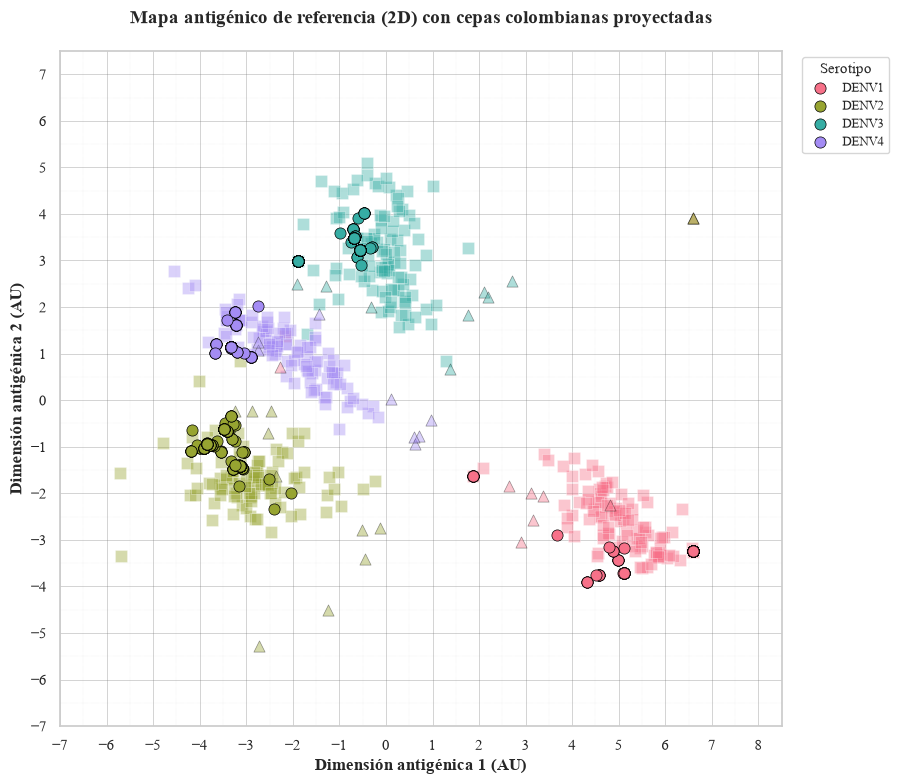

In [166]:
fig, ax = plt.subplots(figsize=(15, 8))
fig.subplots_adjust(
    left=0.10,
    right=0.75,
    bottom=0.12,
    top=0.88
)

# Referencia (Antígenos)
for sero in unique_sero:
    df = antigenos[antigenos["sero"] == sero]
    ax.scatter(
        df["coord1"], df["coord2"],
        color=color_dict[sero],
        marker="s",
        s=65,
        alpha=0.4,
        edgecolors="white",
        linewidth=0.5
    )

# Referencia (Antisueros)
for sero in unique_sero:
    df = sueros[sueros["sero"] == sero]
    ax.scatter(
        df["coord1"], df["coord2"],
        color=color_dict[sero],
        marker="^",
        s=65,
        alpha=0.4,
        edgecolors="black",
        linewidth=0.5
    )

# Cepas Colombianas Proyectadas
for sero in [1, 2, 3, 4]:
    sero_str = f"DENV{sero}"
    if sero in projected_coordinates:
        df_proj = projected_coordinates[sero]
        ax.scatter(
            df_proj["X"], df_proj["Y"],
            color=color_dict[sero_str],
            marker="o",
            s=65,
            alpha=1,
            edgecolors="black",
            linewidth=0.5,
            label=f"{sero_str}"
        )




all_x = np.concatenate([
    antigenos["coord1"].values,
    sueros["coord1"].values,
    *[projected_coordinates[s]["X"].values for s in projected_coordinates]
])
all_y = np.concatenate([
    antigenos["coord2"].values,
    sueros["coord2"].values,
    *[projected_coordinates[s]["Y"].values for s in projected_coordinates]
])

x_min, x_max = np.floor(all_x.min()) - 1, np.ceil(all_x.max()) + 1
y_min, y_max = np.floor(all_y.min()) - 1, np.ceil(all_y.max()) + 1

ax.set_xticks(np.arange(x_min, x_max + 1, 1))
ax.set_yticks(np.arange(y_min, y_max + 1, 1))

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.grid(
    True,
    which="major",
    linestyle="-",
    linewidth=0.6,
    color="gray",
    alpha=0.4
)

ax.set_xticks(np.arange(x_min, x_max + 1, 0.5), minor=True)
ax.set_yticks(np.arange(y_min, y_max + 1, 0.5), minor=True)
ax.grid(
    True,
    which="minor",
    linestyle=":",
    linewidth=0.3,
    color="gray",
    alpha=0.25
)




ax.set_xlabel(
    "Dimensión antigénica 1 (AU)",
    fontsize=12,
    fontweight="bold"
)
ax.set_ylabel(
    "Dimensión antigénica 2 (AU)",
    fontsize=12,
    fontweight="bold"
)
ax.set_title(
    "Mapa antigénico de referencia (2D) con cepas colombianas proyectadas",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.legend(
    title="Serotipo",
    title_fontsize=11,
    fontsize=9,
    frameon=True,
    ncol=1,
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)
ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.savefig(
    "../figures/mapa_proy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [182]:
from joblib import Parallel, delayed
from sklearn.linear_model import Lasso


def _loo_one(m, k, alpha):
    I, J, D, X = m['I'], m['J'], m['D'], m['X']
    n = len(m['ids'])
    test = (I == k) | (J == k)
    train = ~test

    mdl = Lasso(alpha=alpha, positive=True, fit_intercept=False,
                max_iter=5000, tol=1e-3).fit(X[train], D[train])

    others = np.where(I[test] == k, J[test], I[test])        # referencia contraria de cada par
    d_pred = np.clip(X[test] @ mdl.coef_, 0, None)
    d_true = D[test]
    xy = m['ref_xy'][others]

    sero = np.asarray(m['ref_sero'])
    same = sero[others] == sero[k]
    tr_same = sero[I[train]] == sero[J[train]]
    d_null = np.where(same, D[train][tr_same].mean(), D[train][~tr_same].mean())

    proj = lambda d: project_one(d, xy, scale=(1.0, 0.0))
    real = m['ref_xy'][k]
    return dict(
        strainID=m['ids'][k], sero=sero[k],
        err_modelo=np.linalg.norm(proj(d_pred) - real),
        err_oraculo=np.linalg.norm(proj(d_true) - real),   # piso: distancias reales
        err_nulo=np.linalg.norm(proj(d_null) - real),      # solo conoce intra vs inter
        rmse_dist=np.sqrt(np.mean((d_pred - d_true) ** 2)),
        rmse_dist_nulo=np.sqrt(np.mean((d_null - d_true) ** 2)),
    )


def loo_substitution(seq_ref, dfs_list, mapa_ag, alpha=1e-3, n_ref=None,
                     seed=0, n_jobs=4):
    m = _setup(seq_ref, dfs_list, mapa_ag)
    n = len(m['ids'])
    ks = np.arange(n)
    if n_ref is not None:                                   # submuestra para una prueba rápida
        ks = np.random.default_rng(seed).choice(n, n_ref, replace=False)
    rows = Parallel(n_jobs=n_jobs)(delayed(_loo_one)(m, int(k), alpha) for k in ks)
    return pd.DataFrame(rows)

In [183]:
res = loo_substitution(seq_ref, dfs_epi_grantham_val, mapa_ag, alpha=1e-3, n_ref=40)

print(res[["err_modelo", "err_oraculo", "err_nulo", "rmse_dist", "rmse_dist_nulo"]].describe().round(2))
print(res.groupby("sero")[["err_modelo", "err_oraculo", "err_nulo"]].median().round(2))

# Completo (385 ajustes)
res = loo_substitution(seq_ref, dfs_epi_grantham_val, mapa_ag, alpha=1e-3)
res.to_csv("../resources/colombia_data/loo_sustituciones.csv", index=False)

       err_modelo  err_oraculo  err_nulo  rmse_dist  rmse_dist_nulo
count       40.00         40.0     40.00      40.00           40.00
mean         1.26          0.0      1.84       1.26            2.10
std          1.46          0.0      1.10       1.02            0.61
min          0.05          0.0      0.44       0.64            1.17
25%          0.44          0.0      1.32       0.83            1.76
50%          0.88          0.0      1.56       0.95            1.96
75%          1.37          0.0      2.26       1.21            2.40
max          8.06          0.0      6.87       6.15            4.88
      err_modelo  err_oraculo  err_nulo
sero                                   
1           0.68          0.0      1.56
2           1.04          0.0      1.91
3           0.84          0.0      1.56
4           0.99          0.0      1.27


In [185]:
print(res[["err_modelo", "err_oraculo", "err_nulo", "rmse_dist", "rmse_dist_nulo"]].describe().round(2))
print(res.groupby("sero")[["err_modelo", "err_oraculo", "err_nulo"]].median().round(2))

       err_modelo  err_oraculo  err_nulo  rmse_dist  rmse_dist_nulo
count      385.00       385.00    385.00     385.00          385.00
mean         0.90         0.00      1.69       1.01            2.06
std          0.70         0.08      0.78       0.44            0.44
min          0.05         0.00      0.12       0.62            1.03
25%          0.46         0.00      1.19       0.80            1.77
50%          0.75         0.00      1.61       0.89            2.00
75%          1.17         0.00      2.14       1.11            2.42
max          8.06         1.60      6.87       6.15            4.88
      err_modelo  err_oraculo  err_nulo
sero                                   
1           0.75          0.0      1.51
2           0.70          0.0      1.66
3           0.74          0.0      1.60
4           0.77          0.0      1.43


In [186]:
from joblib import Parallel, delayed
from sklearn.linear_model import Lasso


def _loo_one(m, k, alpha):
    I, J, D, X = m['I'], m['J'], m['D'], m['X']
    sero = np.asarray(m['ref_sero'])
    test = (I == k) | (J == k)
    train = ~test

    mdl = Lasso(alpha=alpha, positive=True, fit_intercept=False,
                max_iter=5000, tol=1e-3).fit(X[train], D[train])

    others = np.where(I[test] == k, J[test], I[test])
    d_pred = np.clip(X[test] @ mdl.coef_, 0, None)
    xy = m['ref_xy'][others]

    real = m['ref_xy'][k]
    proj = project_one(d_pred, xy, scale=(1.0, 0.0))

    # línea base de tu figura: media del serotipo sin la propia cepa
    mask = (sero == sero[k]) & (np.arange(len(sero)) != k)
    mean = m['ref_xy'][mask].mean(axis=0)

    return dict(strainID=m['ids'][k], sero=sero[k],
                real_X=real[0], real_Y=real[1],
                proj_X=proj[0], proj_Y=proj[1],
                mean_X=mean[0], mean_Y=mean[1])


def loo_base(seq_ref, dfs_list, mapa_ag, alpha=1e-3, n_jobs=4):
    m = _setup(seq_ref, dfs_list, mapa_ag)
    rows = Parallel(n_jobs=n_jobs)(
        delayed(_loo_one)(m, k, alpha) for k in range(len(m['ids'])))
    df = pd.DataFrame(rows).set_index('strainID')
    return {s: df[df.sero.astype(str) == str(s)].drop(columns='sero')
            for s in (1, 2, 3, 4)}

Serotipo   n    r_X      p_X    r_Y      p_Y    R²_X    R²_Y   RMSE  RMSE_media  Mejora_vs_media    MAE  Mediana Error
  DENV-1 105 0.0774 4.33e-01 0.0885 3.69e-01 -0.0969 -0.1121 1.3491      1.2977          -0.0396 0.9405         0.7464
  DENV-2  86 0.0524 6.32e-01 0.2930 6.19e-03 -0.1200  0.0282 1.1123      1.0848          -0.0253 0.8947         0.6986
  DENV-3 102 0.2167 2.87e-02 0.6642 2.73e-14 -0.1310  0.4235 0.9675      1.1197           0.1359 0.8446         0.7420
  DENV-4  92 0.3616 3.98e-04 0.3162 2.14e-03  0.0773  0.0079 1.0621      1.1038           0.0377 0.9025         0.7701


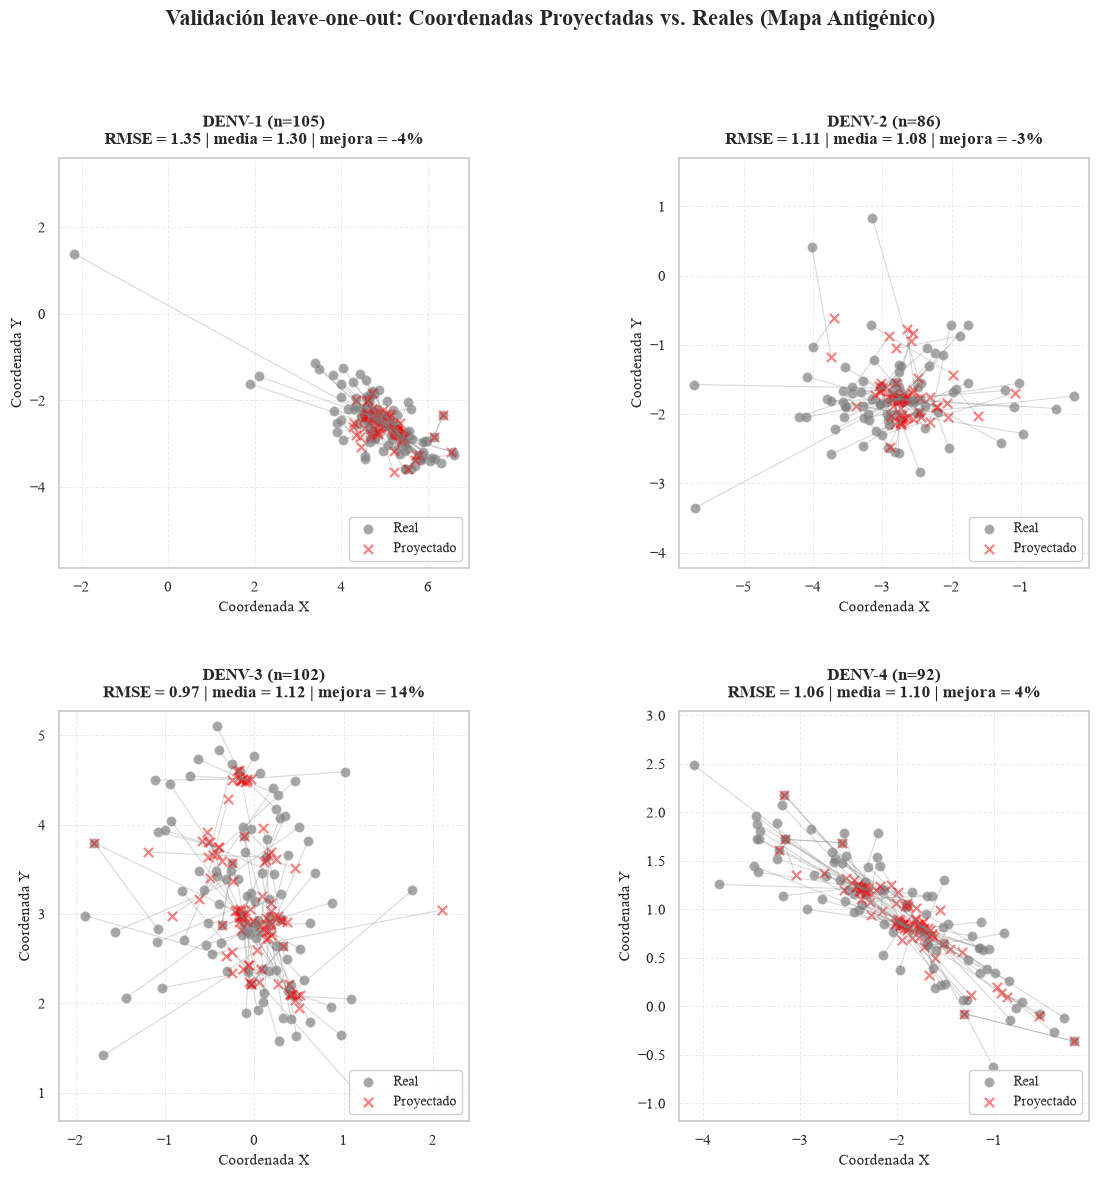

In [187]:
# 1) Validación leave-one-out (reemplaza project_strains_self)
base = loo_base(seq_ref, dfs_epi_grantham_val, mapa_ag, alpha=1e-3)

# 2) Mismo formato que antes: validation_results[sero] con error_X, error_Y, euclidean_error
validation_results = {}
for sero in [1, 2, 3, 4]:
    df_val = base[sero].reset_index()          # strainID vuelve a ser columna
    df_val['error_X'] = df_val['proj_X'] - df_val['real_X']
    df_val['error_Y'] = df_val['proj_Y'] - df_val['real_Y']
    df_val['euclidean_error'] = np.sqrt(df_val['error_X']**2 + df_val['error_Y']**2)
    # error de la línea base (media del serotipo sin la propia cepa)
    df_val['euclidean_error_media'] = np.sqrt((df_val['mean_X'] - df_val['real_X'])**2 +
                                              (df_val['mean_Y'] - df_val['real_Y'])**2)
    validation_results[sero] = df_val

# 3) Tabla resumen
summary_rows = []
for sero in [1, 2, 3, 4]:
    df_val = validation_results[sero]
    r_x, p_x = stats.pearsonr(df_val['real_X'], df_val['proj_X'])
    r_y, p_y = stats.pearsonr(df_val['real_Y'], df_val['proj_Y'])

    ss_res_x = np.sum(df_val['error_X']**2)
    ss_tot_x = np.sum((df_val['real_X'] - df_val['real_X'].mean())**2)
    r2_x = 1 - ss_res_x / ss_tot_x if ss_tot_x > 0 else 0

    ss_res_y = np.sum(df_val['error_Y']**2)
    ss_tot_y = np.sum((df_val['real_Y'] - df_val['real_Y'].mean())**2)
    r2_y = 1 - ss_res_y / ss_tot_y if ss_tot_y > 0 else 0

    rmse = np.sqrt(np.mean(df_val['euclidean_error']**2))
    rmse_media = np.sqrt(np.mean(df_val['euclidean_error_media']**2))

    summary_rows.append({
        'Serotipo': f'DENV-{sero}',
        'n': len(df_val),
        'r_X': round(r_x, 4), 'p_X': f'{p_x:.2e}',
        'r_Y': round(r_y, 4), 'p_Y': f'{p_y:.2e}',
        'R²_X': round(r2_x, 4), 'R²_Y': round(r2_y, 4),
        'RMSE': round(rmse, 4),
        'RMSE_media': round(rmse_media, 4),
        'Mejora_vs_media': round(1 - rmse / rmse_media, 4),
        'MAE': round(df_val['euclidean_error'].mean(), 4),
        'Mediana Error': round(df_val['euclidean_error'].median(), 4)
    })

df_summary = pd.DataFrame(summary_rows)
print(df_summary.to_string(index=False))

# 4) Figura: paneles cuadrados, con RMSE y mejora vs. media en cada título
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes = axes.flatten()

for idx, sero in enumerate([1, 2, 3, 4]):
    df_val = validation_results[sero]
    ax = axes[idx]
    row = df_summary.iloc[idx]

    for i in range(len(df_val)):
        ax.plot([df_val.iloc[i]['real_X'], df_val.iloc[i]['proj_X']],
                [df_val.iloc[i]['real_Y'], df_val.iloc[i]['proj_Y']],
                color='gray', alpha=0.3, linewidth=0.8)

    ax.scatter(df_val['real_X'], df_val['real_Y'], alpha=0.7, s=45,
               c='grey', label='Real', marker='o', edgecolors='darkgrey', linewidth=0.5)
    ax.scatter(df_val['proj_X'], df_val['proj_Y'], alpha=0.5, s=45,
               c='red', label='Proyectado', marker='x', linewidth=1.5)

    all_x = np.concatenate([df_val['real_X'], df_val['proj_X']])
    all_y = np.concatenate([df_val['real_Y'], df_val['proj_Y']])
    cx, cy = (all_x.min() + all_x.max()) / 2, (all_y.min() + all_y.max()) / 2
    half = max(all_x.max() - all_x.min(), all_y.max() - all_y.min()) / 2 * 1.08
    ax.set_xlim(cx - half, cx + half)
    ax.set_ylim(cy - half, cy + half)
    ax.set_box_aspect(1)
    ax.set_aspect('equal')

    ax.set_title(f'DENV-{sero} (n={row["n"]})\n'
                 f'RMSE = {row["RMSE"]:.2f} | media = {row["RMSE_media"]:.2f} | '
                 f'mejora = {row["Mejora_vs_media"]*100:.0f}%',
                 fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel('Coordenada X', fontsize=11)
    ax.set_ylabel('Coordenada Y', fontsize=11)
    ax.legend(fontsize=10, loc='lower right', framealpha=0.9)
    ax.grid(alpha=0.4, linestyle='--', linewidth=0.7)

plt.suptitle('Validación leave-one-out: Coordenadas Proyectadas vs. Reales (Mapa Antigénico)',
             fontsize=16, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.subplots_adjust(hspace=0.35, wspace=0.25)
plt.savefig('../figures/validation_projected_vs_real.png', dpi=300, bbox_inches='tight')
plt.show()

In [188]:
gen = antigenos.set_index("strainID")["genotype"].astype(str)
rows = []
for s, df in base.items():
    g = gen.reindex(df.index).fillna("NA").to_numpy()
    xy = df[["real_X", "real_Y"]].to_numpy()
    cen = df[["mean_X", "mean_Y"]].to_numpy()
    pr = df[["proj_X", "proj_Y"]].to_numpy()
    gm = np.array([xy[(g == g[i]) & (np.arange(len(g)) != i)].mean(axis=0)
                   if ((g == g[i]) & (np.arange(len(g)) != i)).any() else cen[i]
                   for i in range(len(g))])
    rm = lambda p: np.sqrt(np.mean(np.sum((p - xy) ** 2, axis=1)))
    lam, r_c = min(((l, rm(cen + l * (pr - cen))) for l in np.linspace(0, 1, 11)),
                   key=lambda t: t[1])
    rows.append(dict(sero=s, rmse_modelo=rm(pr), rmse_serotipo=rm(cen),
                     rmse_genotipo=rm(gm), lam_opt=lam, rmse_contraido=r_c))
print(pd.DataFrame(rows).round(3))

   sero  rmse_modelo  rmse_serotipo  rmse_genotipo  lam_opt  rmse_contraido
0     1        1.349          1.298          1.313      0.3           1.291
1     2        1.112          1.085          1.077      0.4           1.071
2     3        0.967          1.120          1.021      0.7           0.942
3     4        1.062          1.104          1.076      0.6           1.032


In [189]:
# Grantham calibrado, con las funciones que ya definiste
errors, preds = loo_validation(dfs_epi_grantham_val, mapa_ag)
A_ref, ref_xy, ref_sero, ids = prepare(dfs_epi_grantham_val, mapa_ag)

# modelo de sustituciones: la tabla `res` del LOO por cepa (columna err_modelo)
e_sust = res.set_index("strainID").loc[ids, "err_modelo"].to_numpy()
e_gran = np.linalg.norm(preds - ref_xy, axis=1)

rows = []
for s in ("1", "2", "3", "4"):
    idx = np.where(np.asarray(ref_sero).astype(str) == s)[0]
    real = ref_xy[idx]
    cen = (real.sum(axis=0) - real) / (len(idx) - 1)         # centroide sin la propia cepa
    rm = lambda e: np.sqrt(np.mean(e ** 2))
    rows.append(dict(sero=s, n=len(idx),
                     rmse_grantham=rm(e_gran[idx]),
                     rmse_sustituciones=rm(e_sust[idx]),
                     rmse_centroide=rm(np.linalg.norm(cen - real, axis=1))))
print(pd.DataFrame(rows).round(3))
print("correlación de errores por cepa:", np.corrcoef(e_gran, e_sust)[0, 1].round(2))

  sero    n  rmse_grantham  rmse_sustituciones  rmse_centroide
0    1  105          1.260               1.349           1.298
1    2   86          1.171               1.112           1.085
2    3  102          1.081               0.967           1.120
3    4   92          1.085               1.062           1.104
correlación de errores por cepa: 0.81


In [190]:
def boot_diff(e_a, e_b, n=5000, seed=0):
    """RMSE(a) - RMSE(b), con IC 95% remuestreando cepas."""
    rng = np.random.default_rng(seed)
    rm = lambda e: np.sqrt(np.mean(e ** 2))
    d = []
    for _ in range(n):
        i = rng.integers(0, len(e_a), len(e_a))
        d.append(rm(e_a[i]) - rm(e_b[i]))
    return rm(e_a) - rm(e_b), np.percentile(d, [2.5, 97.5])

for s in ("1", "2", "3", "4"):
    idx = np.where(np.asarray(ref_sero).astype(str) == s)[0]
    real = ref_xy[idx]
    e_cen = np.linalg.norm((real.sum(axis=0) - real) / (len(idx) - 1) - real, axis=1)
    for nombre, e in (("grantham", e_gran[idx]), ("sustituciones", e_sust[idx])):
        dif, ic = boot_diff(e, e_cen)
        print(f"DENV-{s} {nombre} - centroide: {dif:+.3f}  IC95% [{ic[0]:+.3f}, {ic[1]:+.3f}]")

DENV-1 grantham - centroide: -0.037  IC95% [-0.116, +0.057]
DENV-1 sustituciones - centroide: +0.051  IC95% [-0.047, +0.183]
DENV-2 grantham - centroide: +0.086  IC95% [+0.006, +0.173]
DENV-2 sustituciones - centroide: +0.027  IC95% [-0.051, +0.109]
DENV-3 grantham - centroide: -0.039  IC95% [-0.241, +0.208]
DENV-3 sustituciones - centroide: -0.152  IC95% [-0.262, -0.036]
DENV-4 grantham - centroide: -0.019  IC95% [-0.139, +0.104]
DENV-4 sustituciones - centroide: -0.042  IC95% [-0.161, +0.075]
